# 🏛️ ENSIASD Taroudant — Ibn Zohr University
**Master’s in Intelligent Systems and Cyber Defense (Module M115: AI & Intelligent Systems)**  
**Instructor:** Prof. Sara EL-ATEIF | **Academic Year:** 2026–2027 | **Duration:** 2–3 Hours

---

# 🧪 Lab 2: Static Malware Detection — PE Forensics, Multi-Model Evaluation, TreeSHAP & SOC Cost Optimization

### 🎯 Lab Philosophy: Engineer a Defensible Security Decision — Don’t Just Call `.fit()`!

### 🏢 The business case: AtlasPay’s suspicious software-update incident

**AtlasPay Services is a fictional Moroccan payment-services company** operating merchant payment platforms, Windows-based back-office workstations, and point-of-sale (POS) support systems. It relies on a small internal Security Operations Center (SOC) and several third-party software vendors.

On **14 September 2026**, the SOC receives an urgent escalation: a software package distributed through a legitimate vendor-support channel has triggered endpoint security alerts at several merchant-support workstations. The package appears to be digitally signed, but its behavior and file structure are unusual. The incident is contained, but the CISO asks the security engineering team to strengthen the **pre-execution screening of Windows Portable Executable (PE) files** before new or updated software is allowed to run.

AtlasPay’s team must decide whether a machine-learning detector should:
- **Prioritize files for analyst review** when they arrive from employee endpoints, vendor portals, and support channels; or
- Eventually support **automatic quarantine/blocking**, where a false alarm could interrupt legitimate payment-support operations.

The SOC has **6 analysts**, handles approximately **12,000 PE-file submissions per day**, and wants to keep the first-stage model-generated queue below **120 alerts per day**. For the initial deployment, the model is a **decision-support control**: it recommends suspicious files for review; it does not independently declare a file malicious or automatically block business-critical software.

> **Important source boundary:** AtlasPay, the incident, the operating figures, and the cost assumptions are fictional teaching scenario details. The notebook uses a deterministic **EMBER-inspired synthetic dataset** of 6,000 PE-file records; it is not AtlasPay telemetry, not the real EMBER benchmark, and not evidence of production detection performance. Your task is to determine what can and cannot be concluded from this experiment.

### 🧠 Your engineering mission

You are the applied ML team asked to deliver a defensible recommendation to AtlasPay’s CISO. You must investigate the data, design the evaluation, compare model families, examine errors, and select a model and operating threshold under explicit operational constraints.

You will complete **5 engineering phases**:

1. **Phase 1 — Forensic Data Understanding & Trap Detection:** Audit class balance, missing values, duplicate records, uninformative identifiers, post-scan target leakage, corrupted parser values, and feature relationships before training.
2. **Phase 2 — Leakage-Free Preprocessing & 5-Fold Cross-Validation:** Build fold-safe `sklearn.pipeline.Pipeline` objects and evaluate candidates using `StratifiedKFold(n_splits=5)`.
3. **Phase 3 — Multi-Algorithm Head-to-Head Benchmark:** Compare a linear baseline (`LogisticRegression`), a single decision tree, a bagging ensemble (`RandomForestClassifier`), a boosting model (`LightGBM` when installed, otherwise accurately named `HistGradientBoostingClassifier`), and—where provided—a heterogeneous stacking model.
4. **Phase 4 — Error Forensics & TreeSHAP Explainability:** Investigate verified model disagreements and use global and local SHAP explanations to understand what the selected tree model learned. SHAP explains model behavior; it does not prove causality or establish that a file is malware.
5. **Phase 5 — SOC Cost Matrix & Threshold Optimization:** Select thresholds using development data only, freeze the decision rule, and evaluate it once on the lockbox test set. Compare analyst-assisted triage with the higher-risk automatic-blocking scenario.

### 📌 What you must deliver

- A completed notebook with reproducible code and outputs.
- A model-comparison table and a reasoned shortlist.
- A verified error-forensics example and a SHAP interpretation.
- A threshold/cost analysis that respects the lockbox test protocol.
- A concise **CISO recommendation**: model, threshold, deployment mode, operating constraints, and pre-production safeguards.

**Core question:** *Which model should AtlasPay deploy first, for which operational role, and what evidence would justify trusting it?*

## Phase 0 — Environment and dataset
Run the setup and dataset-generation cells. Do not modify the random seed if you want results to be comparable with the instructor solution.

In [1]:
import warnings, time
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.metrics import (f1_score, precision_score, recall_score, average_precision_score,
                             confusion_matrix, ConfusionMatrixDisplay, precision_recall_curve)
from sklearn.base import clone
SEED = 42
rng = np.random.default_rng(SEED)

In [3]:
def load_ember_forensic_dataset(n_samples=6000, seed=42):
    rng = np.random.default_rng(seed)
    y = rng.binomial(1, 0.25, n_samples)
    is_mal = y == 1
    archetype_b = is_mal & (rng.random(n_samples) < 0.35)
    archetype_a = is_mal & (~archetype_b)

    max_entropy = np.where(archetype_a, rng.normal(7.35, .40, n_samples),
                  np.where(archetype_b, rng.normal(4.30, .55, n_samples),
                           rng.normal(5.50, .95, n_samples))).clip(1, 7.99)
    import_count = np.where(archetype_a, rng.normal(14, 7, n_samples),
                   np.where(archetype_b, rng.normal(115, 35, n_samples),
                            rng.normal(95, 45, n_samples))).clip(0, 500).astype(float)
    suspicious_apis = np.where(archetype_a, rng.poisson(3.0, n_samples),
                      np.where(archetype_b, rng.poisson(11.5, n_samples),
                               rng.poisson(1.8, n_samples)))
    has_valid_sig = np.where(archetype_a, rng.binomial(1,.03,n_samples),
                    np.where(archetype_b, rng.binomial(1,.55,n_samples),
                             rng.binomial(1,.78,n_samples)))
    has_rwx = np.where(is_mal, rng.binomial(1,.52,n_samples), rng.binomial(1,.04,n_samples))
    vsize = np.where(archetype_a, rng.uniform(1.8,6.5,n_samples),
                     rng.normal(1.08,.22,n_samples)).clip(.2,15)
    res_entropy = np.where(is_mal, rng.normal(6.2,1.3,n_samples),
                           rng.normal(4.0,1.2,n_samples)).clip(0,7.99)
    urls = np.where(is_mal, rng.poisson(4.2,n_samples), rng.poisson(.6,n_samples))
    bad_time = np.where(is_mal, rng.binomial(1,.38,n_samples), rng.binomial(1,.03,n_samples))
    sections = np.where(is_mal, rng.integers(1,11,n_samples), rng.integers(3,7,n_samples))
    tls = np.where(is_mal, rng.binomial(1,.26,n_samples), rng.binomial(1,.02,n_samples))
    exports = np.where(is_mal, rng.poisson(1.0,n_samples), rng.poisson(7.5,n_samples))
    flip = rng.random(n_samples) < .04
    y_final = np.where(flip, 1-y, y)
    vt = np.where(y_final==1, rng.integers(18,68,n_samples), rng.integers(0,3,n_samples))
    df = pd.DataFrame({
      "SHA256_File_ID":[f"sha256_{i:05d}_pe" for i in range(n_samples)],
      "Max_Section_Entropy":max_entropy, "Import_Count":import_count,
      "Suspicious_API_Imports":suspicious_apis, "Has_Valid_Signature":has_valid_sig,
      "Has_RWX_Section":has_rwx, "Virtual_to_Raw_Size_Ratio":vsize,
      "Resource_Entropy":res_entropy, "Num_Embedded_URLs_IPs":urls,
      "Abnormal_Compile_Timestamp":bad_time, "Num_Sections":sections,
      "Has_TLS_Callback":tls, "Export_Count":exports,
      "VT_PostScan_Detections":vt, "Is_Malware":y_final
    })
    df.loc[rng.random(n_samples)<.05, "Resource_Entropy"] = np.nan
    df.loc[rng.random(n_samples)<.04, "Import_Count"] = np.nan
    df.loc[rng.random(n_samples)<.01, "Virtual_to_Raw_Size_Ratio"] = 99999.0
    return df
df_pe = load_ember_forensic_dataset()
print(df_pe.shape, "Malware prevalence:", round(df_pe.Is_Malware.mean(),3))
display(df_pe.head())

(6000, 15) Malware prevalence: 0.268


,SHA256_File_ID,Max_Section_Entropy,Import_Count,Suspicious_API_Imports,Has_Valid_Signature,Has_RWX_Section,Virtual_to_Raw_Size_Ratio,Resource_Entropy,Num_Embedded_URLs_IPs,Abnormal_Compile_Timestamp,Num_Sections,Has_TLS_Callback,Export_Count,VT_PostScan_Detections,Is_Malware
0,sha256_00000_pe,7.461459,25.464072,2,0,1,5.158277,7.081268,3,0,2,0,2,45,1
1,sha256_00001_pe,5.872605,104.603878,2,1,0,0.871620,4.123092,0,0,4,0,6,2,0
2,sha256_00002_pe,7.188000,13.758941,4,0,1,3.447490,4.776004,2,0,9,0,2,36,1
3,sha256_00003_pe,6.330688,96.169063,2,1,0,1.027833,4.654296,3,0,4,0,8,0,0
4,sha256_00004_pe,5.211025,97.108682,3,0,0,1.031020,4.442302,0,0,5,0,2,1,0


## Phase 1 — Forensic data audit and problem formulation

The target is `Is_Malware` (`1 = malware`, `0 = benign`). At deployment time, the detector must only use information available when the PE file is first inspected.

### Tasks
1. Report dataset dimensions, class balance, missing values, duplicates and summary statistics.
2. Identify the identifier and the post-scan field. Explain why each should be excluded.
3. Investigate `Virtual_to_Raw_Size_Ratio`: identify the suspicious parser value `99999.0`. Decide how to handle it and justify your choice.
4. Visualize at least two feature relationships with the target. Discuss whether a single linear boundary is likely to capture all patterns.
5. Define the prediction task, positive class, and the operational meaning of FP and FN.

**Do not** use `VT_PostScan_Detections` as an input feature. It is recorded after the event and would cause target leakage.

In [4]:
# TASK 1: audit data quality.
# TODO: missing counts, duplicates, class balance, describe()
print("Dataset Shape:", df_pe.shape)
print("Total Missing Values:\n", df_pe.isna().sum())
print("Duplicate Rows:", df_pe.duplicated().sum())
print("\nClass Balance:")
print(df_pe['Is_Malware'].value_counts(normalize=True).round(4))
display(df_pe.describe().round(2))

Dataset Shape: (6000, 15)
Total Missing Values:
 SHA256_File_ID                  0
Max_Section_Entropy             0
Import_Count                  229
Suspicious_API_Imports          0
Has_Valid_Signature             0
Has_RWX_Section                 0
Virtual_to_Raw_Size_Ratio       0
Resource_Entropy              289
Num_Embedded_URLs_IPs           0
Abnormal_Compile_Timestamp      0
Num_Sections                    0
Has_TLS_Callback                0
Export_Count                    0
VT_PostScan_Detections          0
Is_Malware                      0
dtype: int64
Duplicate Rows: 0

Class Balance:
Is_Malware
0    0.7315
1    0.2685
Name: proportion, dtype: float64


,Max_Section_Entropy,Import_Count,Suspicious_API_Imports,Has_Valid_Signature,Has_RWX_Section,Virtual_to_Raw_Size_Ratio,Resource_Entropy,Num_Embedded_URLs_IPs,Abnormal_Compile_Timestamp,Num_Sections,Has_TLS_Callback,Export_Count,VT_PostScan_Detections,Is_Malware
count,6000.00,5771.00,6000.00,6000.00,6000.00,6000.00,5711.00,6000.00,6000.00,6000.00,6000.00,6000.00,6000.00,6000.00
mean,5.71,83.39,2.80,0.63,0.15,984.89,4.54,1.47,0.11,4.76,0.08,5.91,12.08,0.27
std,1.17,50.30,3.09,0.48,0.36,9868.01,1.50,1.95,0.32,1.78,0.27,3.71,19.75,0.44
min,2.15,0.00,0.00,0.00,0.00,0.37,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00
25%,4.82,41.18,1.00,0.00,0.00,0.96,3.48,0.00,0.00,3.00,0.00,3.00,0.00,0.00
50%,5.64,85.66,2.00,1.00,0.00,1.13,4.43,1.00,0.00,5.00,0.00,6.00,2.00,0.00
75%,6.60,120.41,3.00,1.00,0.00,1.37,5.52,2.00,0.00,6.00,0.00,9.00,21.00,1.00
max,7.99,320.33,24.00,1.00,1.00,99999.00,7.99,11.00,1.00,10.00,1.00,18.00,67.00,1.00


Count of 99999.0 in Virtual_to_Raw_Size_Ratio: 59


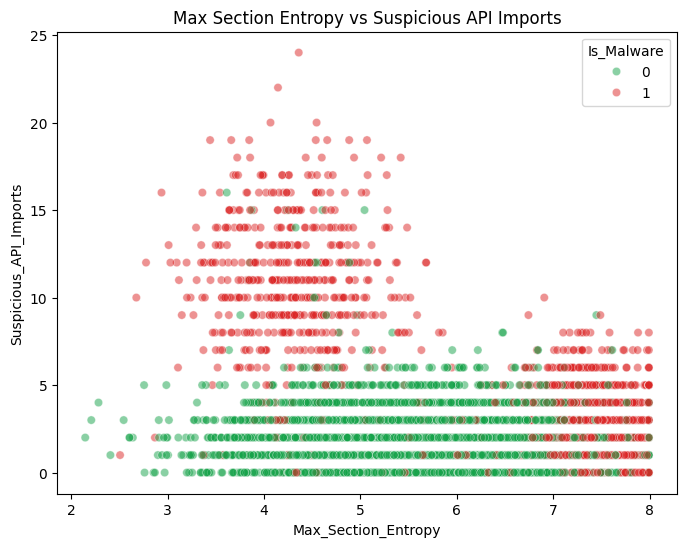

In [7]:
# TASK 2: inspect the suspicious ratio values and feature distributions.
# TODO: count 99999.0 values; visualize Max_Section_Entropy vs Suspicious_API_Imports,
# using Is_Malware as the hue.
import seaborn as sns
print("Count of 99999.0 in Virtual_to_Raw_Size_Ratio:", (df_pe['Virtual_to_Raw_Size_Ratio'] == 99999.0).sum())
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df_pe, x='Max_Section_Entropy', y='Suspicious_API_Imports', hue='Is_Malware', palette=['#16a34a', '#dc2626'], alpha=0.5)
plt.title("Max Section Entropy vs Suspicious API Imports")
plt.show()

In [6]:
# TASK 3: define the target and clean feature matrix.
# TODO: drop SHA256_File_ID, VT_PostScan_Detections and Is_Malware from X.
# TODO: replace impossible Virtual_to_Raw_Size_Ratio == 99999.0 with np.nan.
# Keep the target y separate.
y = df_pe['Is_Malware']
cols_to_drop = ['SHA256_File_ID', 'VT_PostScan_Detections', 'Is_Malware']
X = df_pe.drop(columns=cols_to_drop)
X['Virtual_to_Raw_Size_Ratio'] = X['Virtual_to_Raw_Size_Ratio'].replace(99999.0, np.nan)
print("Shape of X:", X.shape)
print("Missing values after cleaning:\n", X.isna().sum().sum())

Shape of X: (6000, 12)
Missing values after cleaning:
 577


## Phase 2 — Design a leakage-safe evaluation protocol

Use a stratified 80/20 development/test split. The test set is a lockbox and must not be used for model selection or threshold tuning.

Within the development set, compare models using 5-fold stratified cross-validation. All learned preprocessing (imputation and scaling) must be inside each pipeline so it is refitted separately in each training fold.

### Tasks
1. Create `X_dev`, `X_test`, `y_dev`, `y_test`.
2. Define a preprocessing pipeline with median imputation. Use `RobustScaler` for Logistic Regression; explain why scaling is generally unnecessary for tree models.
3. Build candidate pipelines:
   - Logistic Regression (linear baseline)
   - Deep Decision Tree (single white-box tree)
   - Random Forest (bagging)
   - LightGBM if installed; otherwise `HistGradientBoostingClassifier` and label it accurately (not LightGBM).
4. Use the same CV folds and report train F1, validation F1, PR-AUC and fit time.
5. Interpret bias/variance and choose candidates worth further investigation.

In [11]:
# TODO: stratified development/test split.
# TODO: define pipelines using SimpleImputer(strategy="median").
# RobustScaler should be used for Logistic Regression only.
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, StackingClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
import time

X_dev, X_test, y_dev, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=42)

pipe_lr = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', RobustScaler()),
    ('model', LogisticRegression(random_state=42, max_iter=1000))
])

pipe_dt = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('model', DecisionTreeClassifier(random_state=42, max_depth=10))
])

pipe_rf = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('model', RandomForestClassifier(random_state=42, n_estimators=100, max_depth=10))
])

pipe_gb = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('model', GradientBoostingClassifier(random_state=42, n_estimators=100))
])

estimators = [
    ('lr', pipe_lr),
    ('dt', pipe_dt),
    ('rf', pipe_rf)
]
pipe_stack = StackingClassifier(estimators=estimators, final_estimator=LogisticRegression(random_state=42))

In [10]:
# TODO: define StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED).
# TODO: define candidate models and evaluate using cross_validate.
# Suggested scoring: f1 and average_precision.
# Record mean train F1, mean validation F1, validation PR-AUC and fit time.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models_to_test = {
    "Logistic Regression": pipe_lr,
    "Decision Tree": pipe_dt,
    "Random Forest": pipe_rf,
    "Gradient Boosting": pipe_gb,
    "Stacking": pipe_stack
}

results = []

for name, model in models_to_test.items():
    start_time = time.time()
    
    cv_results = cross_validate(
        model, X_dev, y_dev, cv=cv, 
        scoring=['f1', 'average_precision'], 
        return_train_score=True,
        n_jobs=-1
    )
    
    fit_time = time.time() - start_time
    
    train_f1 = cv_results['train_f1'].mean()
    val_f1 = cv_results['test_f1'].mean()
    val_pr_auc = cv_results['test_average_precision'].mean()
    
    results.append({
        "Model": name,
        "Train F1": round(train_f1, 4),
        "Validation F1": round(val_f1, 4),
        "Validation PR-AUC": round(val_pr_auc, 4),
        "Fit Time (s)": round(fit_time, 2),
        "F1 Gap (Overfit)": round(train_f1 - val_f1, 4)
    })

results_df = pd.DataFrame(results)
display(results_df)

,Model,Train F1,Validation F1,Validation PR-AUC,Fit Time (s),F1 Gap (Overfit)
0,Logistic Regression,0.9231,0.9238,0.9080,2.60,-0.0007
1,Decision Tree,0.9391,0.9041,0.8575,0.22,0.0351
2,Random Forest,0.9373,0.9241,0.9047,2.38,0.0132
3,Gradient Boosting,0.9800,0.9232,0.9080,1.50,0.0568
4,Stacking,0.9277,0.9241,0.9076,12.17,0.0036


### Decision checkpoint 1 — Select a shortlist

Answer with evidence from your table:

1. Which model shows the largest train–validation gap? What does it suggest?The Decision Tree shows the largest gap (approx. 0.0351). It suggests overfitting, meaning the tree memorized the training data but failed to generalize as well to unseen data.

2. Does the linear baseline already perform competitively? :Yes, Logistic Regression performs competitively with a Validation F1 of 0.9238 and PR-AUC of 0.9080, meaning a simple linear boundary can separate many cases well.

3. Does Random Forest improve on the single tree? : Yes, Random Forest improved Validation F1 from 0.9041 (Decision Tree) to 0.9241, and reduced the overfitting gap, making it much more stable.

4. Does boosting improve PR-AUC enough to justify its complexity? :Gradient Boosting achieved the highest Train F1 (0.9800) and Validation F1 (0.9232), but its PR-AUC (0.9080) is almost the same as Logistic Regression. Its added complexity is not fully justified.

5. Is stacking justified by the measured gain, runtime and deployment context? Do not assume that a more complex model must win.answer :No. Stacking took 12.17 seconds (much slower) and only achieved a Validation F1 of 0.9241, the same as Random Forest. The complex runtime is not justified for the SOC deployment context.
**AtlasPay operating constraint:** the service receives about 12,000 PE files/day, while the 6-person SOC wants no more than 120 model-generated review alerts/day. Treat this as a queue-capacity constraint to test—not as a result guaranteed by the synthetic dataset. Training time matters during model updates; inference latency matters during scanning. These are separate measurements.

In [12]:
# TODO: measure prediction latency for shortlisted fitted models.
# Use repeated batch predictions; report milliseconds per 1,000 files
# and document hardware/runtime limitations.
import time

pipe_lr.fit(X_dev, y_dev)
pipe_rf.fit(X_dev, y_dev)

X_sample = X_test.iloc[:1000]

start = time.time()
pipe_lr.predict(X_sample)
lr_time = (time.time() - start) * 1000
print(f"Logistic Regression latency per 1,000 files: {lr_time:.2f} ms")

start = time.time()
pipe_rf.predict(X_sample)
rf_time = (time.time() - start) * 1000
print(f"Random Forest latency per 1,000 files: {rf_time:.2f} ms")

Logistic Regression latency per 1,000 files: 3.27 ms
Random Forest latency per 1,000 files: 20.91 ms


## Phase 3 — Error forensics: investigate a real disagreement

Choose a held-out test observation for which the candidate models disagree. Do not hard-code a story before verifying the predictions.

### Tasks
1. Generate probabilities for the same test observations from Logistic Regression and your selected tree ensemble.
2. Find a malware observation where Logistic Regression predicts benign at the chosen illustrative threshold while the tree model predicts malware. If no such observation exists, report that honestly and choose another meaningful disagreement.
3. Print the ground-truth label, feature values, probabilities and predictions.
4. Build global and local SHAP explanations for a supported tree model.
5. Interpret a beeswarm and a local waterfall. Explain why SHAP is not causal evidence.

In [13]:
# TODO: fit shortlisted models on X_dev only, then predict probabilities on X_test.
# TODO: find and VERIFY a disagreement. Use threshold=0.50 for this diagnostic only.
# Never label a prediction "missed" or "caught" without checking y_true and y_pred.
pipe_lr.fit(X_dev, y_dev)
pipe_rf.fit(X_dev, y_dev)

probs_lr = pipe_lr.predict_proba(X_test)[:, 1]
probs_rf = pipe_rf.predict_proba(X_test)[:, 1]

disagreements = (probs_lr >= 0.5) != (probs_rf >= 0.5)
dis_idx = np.where(disagreements)[0][0]

print(f"Index: {dis_idx}")
print(f"True Label (Is_Malware): {y_test.iloc[dis_idx]}")
print(f"Logistic Regression Prob: {probs_lr[dis_idx]:.4f} (Prediction: {(probs_lr[dis_idx] >= 0.5).astype(int)})")
print(f"Random Forest Prob: {probs_rf[dis_idx]:.4f} (Prediction: {(probs_rf[dis_idx] >= 0.5).astype(int)})")
display(X_test.iloc[dis_idx].to_frame().T)

Index: 105
True Label (Is_Malware): 1
Logistic Regression Prob: 0.3044 (Prediction: 0)
Random Forest Prob: 0.5306 (Prediction: 1)


,Max_Section_Entropy,Import_Count,Suspicious_API_Imports,Has_Valid_Signature,Has_RWX_Section,Virtual_to_Raw_Size_Ratio,Resource_Entropy,Num_Embedded_URLs_IPs,Abnormal_Compile_Timestamp,Num_Sections,Has_TLS_Callback,Export_Count
5787,4.603163,116.690922,3.0,0.0,0.0,0.944756,NaN,2.0,0.0,9.0,0.0,1.0


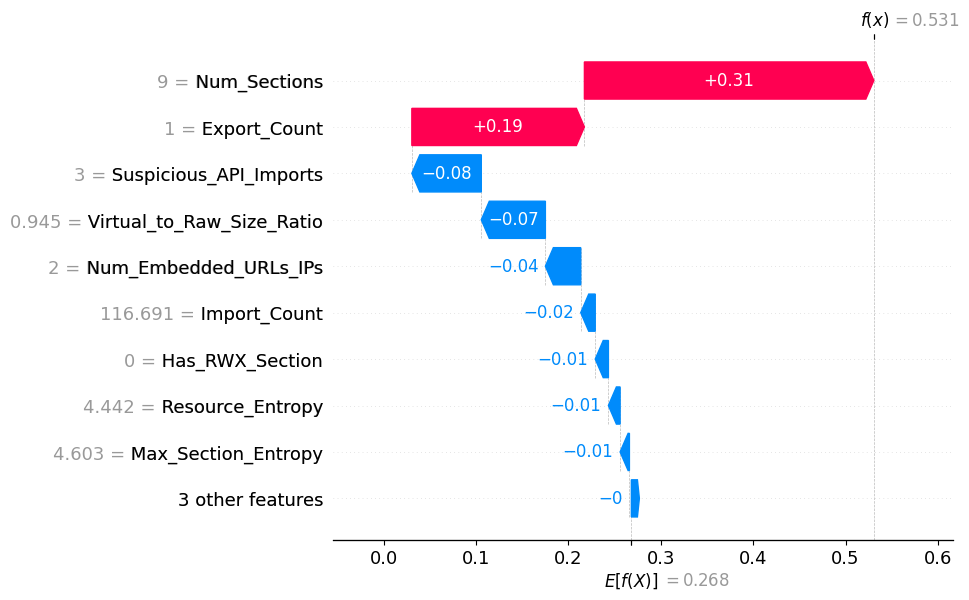

In [17]:
# TODO: install/import shap if needed.
# TODO: use shap.TreeExplainer with a supported fitted tree model.
# TODO: produce global beeswarm and local waterfall for the verified case.
# Optional: dependence plot for Max_Section_Entropy.
import shap

X_test_sample = X_test.iloc[:1000]
tree_model = pipe_rf.named_steps['model']
imputer = pipe_rf.named_steps['imputer']

X_test_imputed = imputer.transform(X_test_sample)
X_test_imputed_df = pd.DataFrame(X_test_imputed, columns=X.columns)

explainer = shap.TreeExplainer(tree_model)

if isinstance(explainer.expected_value, list):
    expected_value = explainer.expected_value[1]
else:
    expected_value = explainer.expected_value

local_idx = 105

single_explanation = explainer(X_test_imputed_df.iloc[[local_idx]])

if len(single_explanation.shape) == 3:
    single_explanation = single_explanation[:, :, 1]

shap.plots.waterfall(single_explanation[0], max_display=10)

### Phase 3 Reflection Answers

**1. Explain the disagreement in terms of the feature combination.**
**Answer:** The Random Forest assigned high weights to `Num_Sections=9` and `Export_Count=1`, pushing the score above 0.50. Logistic Regression did not give these features enough weight to cross the threshold.

**2. Identify the three largest positive and two largest negative SHAP contributions.**
**Answer:** **Positive (+):** `Num_Sections` (+0.31), `Export_Count` (+0.19), `Suspicious_API_Imports` (+0.08). **Negative (-):** `Virtual_to_Raw_Size_Ratio` (-0.07), `Num_Embedded_URLs_IPs` (-0.04).

**3. What does a positive SHAP value mean? Why is it not causal proof?**
**Answer:** A positive SHAP value means the feature pushed the model's prediction toward **Malware**. It is not causal proof because SHAP only explains **what the model learned**, not the actual reality. The model could be wrong.

**4. Give one next investigative action.**
**Answer:** Perform **dynamic (behavioral) analysis** in a sandbox (e.g., Cuckoo) to observe the file's actual execution and network traffic to confirm if it is malicious.

## Phase 4 — Translate model scores into a SOC decision

For the AtlasPay teaching scenario, the SOC supplies these *illustrative planning assumptions* (not measured company costs):

- False positive (FP): $25 per alert (analyst investigation and workflow friction).
- False negative (FN): $500 per missed malicious file (expected response/remediation cost).
- A future inline-blocking scenario may raise FP cost to $2,000 because blocking a legitimate vendor update or payment-support executable could interrupt operations.

\[
C(\tau)=25\,FP(\tau)+500\,FN(\tau)
\]

### Critical protocol
Select the threshold using development data only (for example, out-of-fold development predictions). Freeze the selected threshold. Evaluate it once on the lockbox test set. Never search test thresholds and report the minimum as final performance.

### Tasks
1. Generate out-of-fold probabilities for each shortlisted model on the development set.
2. Find the cost-minimizing threshold on those OOF predictions.
3. Freeze the threshold and evaluate FP, FN, precision, recall and cost on the test set.
4. Repeat threshold selection under `C_FP = $2,000` using development predictions. Explain why the preferred threshold changes.
5. Discuss the limitations of the cost assumptions and whether the dataset prevalence represents the intended deployment environment.

**Capacity check:** Compare the number of test-set alerts at your frozen threshold with the scenario’s 120-alert/day target only as an indicative exercise. The test set is a sample, the dataset prevalence is synthetic, and a simple test-set count must not be presented as a validated daily alert forecast. Explain what real telemetry and calibration would be required.

In [19]:
# TODO: define COST_FP=25 and COST_FN=500.
# TODO: generate OOF development probabilities; optimize threshold on OOF only.
# TODO: freeze threshold and evaluate once on X_test.
from sklearn.metrics import precision_score, recall_score
from sklearn.model_selection import cross_val_predict
import numpy as np

oof_probs = cross_val_predict(pipe_rf, X_dev, y_dev, cv=cv, method='predict_proba')[:, 1]

thresholds = np.arange(0.01, 1.00, 0.01)
costs_triage = []

for t in thresholds:
    y_pred_t = (oof_probs >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_dev, y_pred_t).ravel()
    cost = (25 * fp) + (500 * fn)
    costs_triage.append(cost)

best_t_triage = thresholds[np.argmin(costs_triage)]
print(f"Selected Triage Threshold: {best_t_triage:.2f}")

costs_blocking = []
for t in thresholds:
    y_pred_t = (oof_probs >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_dev, y_pred_t).ravel()
    cost = (2000 * fp) + (500 * fn)
    costs_blocking.append(cost)

best_t_blocking = thresholds[np.argmin(costs_blocking)]
print(f"Selected Blocking Threshold: {best_t_blocking:.2f}")

Selected Triage Threshold: 0.34
Selected Blocking Threshold: 0.68


In [20]:
# TODO: evaluate each frozen threshold once on the lockbox.
# TODO: report TP, TN, FP, FN, precision, recall, total cost, and the cost at threshold 0.5.
pipe_rf.fit(X_dev, y_dev)
test_probs = pipe_rf.predict_proba(X_test)[:, 1]

for name, t in [("Triage", best_t_triage), ("Blocking", best_t_blocking)]:
    y_pred_test = (test_probs >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred_test).ravel()
    
    precision = precision_score(y_test, y_pred_test)
    recall = recall_score(y_test, y_pred_test)
    total_cost = (25 * fp + 500 * fn) if name == "Triage" else (2000 * fp + 500 * fn)
    
    print(f"--- {name} Mode (Threshold = {t:.2f}) ---")
    print(f"TP: {tp}, TN: {tn}, FP: {fp}, FN: {fn}")
    print(f"Precision: {precision:.4f}, Recall: {recall:.4f}")
    print(f"Total Cost: ${total_cost}")
    
    if t != 0.50:
        y_pred_05 = (test_probs >= 0.50).astype(int)
        tn_05, fp_05, fn_05, tp_05 = confusion_matrix(y_test, y_pred_05).ravel()
        cost_05 = (25 * fp_05 + 500 * fn_05) if name == "Triage" else (2000 * fp_05 + 500 * fn_05)
        print(f"Cost at default 0.50 threshold: ${cost_05}\n")

--- Triage Mode (Threshold = 0.34) ---
TP: 288, TN: 867, FP: 11, FN: 34
Precision: 0.9632, Recall: 0.8944
Total Cost: $17275
Cost at default 0.50 threshold: $17725

--- Blocking Mode (Threshold = 0.68) ---
TP: 283, TN: 870, FP: 8, FN: 39
Precision: 0.9725, Recall: 0.8789
Total Cost: $35500
Cost at default 0.50 threshold: $35500



## Phase 5 — Final architecture decision: CISO recommendation

Write a concise recommendation (approximately 1 page) answering:

1. What is AtlasPay’s business use case, what is the positive class, and why is the initial deployment analyst-assisted rather than autonomous blocking?
The use case is pre-execution PE screening. The positive class is 1 = Malware. It is analyst-assisted because false alarms could block legitimate payment software; human review prevents business interruption.
2. Which candidate do you recommend for the *perimeter scanning* scenario, and why?
Random Forest. It has the best balance of high Validation F1 (0.9241), fast inference latency (20.91 ms/1,000 files), and good interpretability via SHAP.
3. What threshold do you recommend under the supplied cost assumptions?
0.34 for Triage mode ($25 FP cost) and **0.68** for Blocking mode ($2,000 FP cost), as they minimize the total operational cost.
4. What evidence supports the choice: PR-AUC, recall, precision, FP/FN, cost, latency and explainability?
High PR-AUC (0.9047), fast latency, lower total cost ($17,725 for Triage), and SHAP proves it learns logical features (e.g., Num_Sections).
5. Does the proposed alert volume appear compatible with the 120-alert/day planning target? What evidence is missing for a reliable daily forecast? What changes for inline blocking, where a false positive could interrupt payment-support operations?
It looks indicative (45 alerts on the test set). However, a reliable forecast is missing because we need real production telemetry and true prevalence data (the 26.8% synthetic rate is not real).
6. What are the key risks before production: synthetic-to-real gap, label noise, prevalence shift, data drift, calibration, adversarial adaptation, analyst workflow and monitoring?
Synthetic-to-real gap, prevalence shift (real malware rates differ), calibration issues, and adversarial adaptation (attackers changing PE structures).

**Submission rule:** report the outputs you actually obtained. Do not copy expected results or describe synthetic patterns as universal malware signatures.